# Myopia binary classification experiment

Exploratory supervised classification using `DATA.xls`, sheet `2018`. This is a research experiment, not a clinically validated diagnostic system. The proposed target is provisional right-eye SER = sphere + cylinder/2, with Myopia for SER ≤ −0.50 D. This is an operational research threshold and must be checked against the relevant clinical definition and refraction measurement protocol. Sphere, cylinder, and SER are excluded from predictors.

The notebook reuses audited exact column names; missing predictors are handled inside fold-fitted sklearn pipelines. No sentinel-like values are automatically recoded. Target-missing rows cannot be labeled and are counted explicitly.


## Reproducible workflow

The evaluation uses an 80:20 stratified split (`random_state=42`) and stratified five-fold out-of-fold predictions on the training partition. Preprocessing is fit within each fold. The held-out test partition is reserved for final performance reporting. Model selection is based on training OOF F1, with sensitivity, PR-AUC, specificity, and ROC-AUC as tie-breaks; test results remain an unbiased final description under this protocol.


{'scikit-learn': '1.7.2', 'xgboost': '3.3.0'}


Verified columns: ['spherical refraction of right eye', 'cylindrical refraction of right eye', 'gender', 'height', 'weight', 'axial length of right eye', 'time of study at weekdays', 'time of study at weekend days', 'time outdoors at weekdays', 'time outdoors at weekend days']
Potential participant/record ID columns: none found by explicit name patterns
Rows: 3658 exact duplicate rows retained: 0
Source missing values: {'spherical refraction of right eye': 0, 'cylindrical refraction of right eye': 0, 'gender': 0, 'height': 0, 'weight': 0, 'axial length of right eye': 0, 'time of study at weekdays': 0, 'time of study at weekend days': 0, 'time outdoors at weekdays': 0, 'time outdoors at weekend days': 0}
Non-numeric or missing after numeric parsing: {'spherical refraction of right eye': 0, 'cylindrical refraction of right eye': 0, 'gender': 0, 'height': 0, 'weight': 0, 'axial length of right eye': 0, 'time of study at weekdays': 0, 'time of study at weekend days': 0, 'time outdoors at w

,min,1%,25%,50%,75%,99%,max
spherical refraction of right eye,-14.00,-7.75,-2.500,-0.50,0.25,2.2500,8.25
cylindrical refraction of right eye,-5.00,-3.25,-0.750,-0.50,-0.25,0.0000,0.00
height,97.70,113.00,129.000,147.00,163.00,183.7150,192.50
weight,16.50,19.10,28.925,42.50,56.20,94.0860,125.00
axial length of right eye,20.01,21.34,22.910,23.67,24.67,27.3586,29.22
time of study at weekdays,0.00,0.00,110.000,150.00,210.00,600.0000,1320.00
time of study at weekend days,0.00,0.00,120.000,180.00,280.00,720.0000,1410.00
time outdoors at weekdays,0.00,0.00,20.000,30.00,60.00,204.3000,960.00
time outdoors at weekend days,0.00,0.00,60.000,90.00,120.00,360.0000,840.00


The -1/-9 refraction values are retained because their meanings cannot be established from this workbook alone; verify their coding before clinical interpretation. Their inclusion may affect target labels.
Target-ineligible observations excluded because SER cannot be constructed: 0; all such rows are counted explicitly.
Total usable labeled observations: 3658


,Class,Count,Percentage
0,Myopia,2116,57.845817
1,Non-Myopia,1542,42.154183


Imbalance assessment: no pronounced imbalance by the prespecified 40% rule


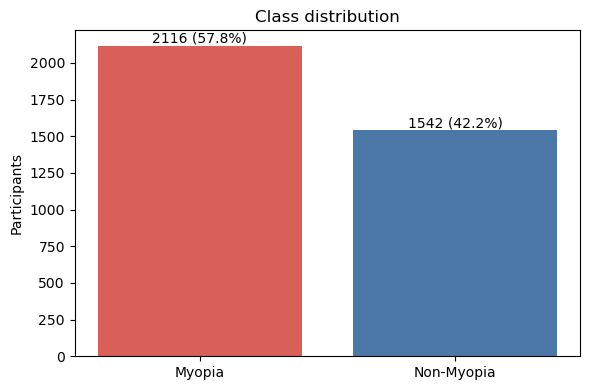

Stratified 80:20 split: 2926 training, 732 test. Test data are not used until final evaluation.
Class weighting: None ; XGBoost scale_pos_weight: 1.0


Five-fold stratified training cross-validation (out-of-fold predictions):


,CV Model,CV Accuracy,CV Precision,CV Recall / Sensitivity,CV Specificity,CV F1-score,CV ROC-AUC,CV PR-AUC
0,Logistic Regression,0.790499,0.825301,0.809214,0.764801,0.817179,0.871126,0.917195
1,Decision Tree,0.710185,0.754059,0.740697,0.668289,0.747318,0.704493,0.708563
2,Random Forest,0.776145,0.821960,0.782634,0.767234,0.801815,0.856404,0.906860
3,XGBoost,0.787081,0.840764,0.779681,0.797242,0.809071,0.864549,0.911603
4,Gradient Boosting,0.785714,0.831468,0.789722,0.780211,0.810058,0.865233,0.913484
5,SVC,0.785714,0.821084,0.805080,0.759124,0.813003,0.859097,0.903840
6,K-Nearest Neighbors,0.754956,0.801235,0.766686,0.738848,0.783580,0.823396,0.851520
7,Extra Trees,0.775120,0.816127,0.789132,0.755880,0.802402,0.852058,0.902544
8,Dummy,0.578606,0.578606,1.000000,0.000000,0.733059,0.499159,0.578157


,Model,Selected on training OOF,Accuracy,Precision,Recall / Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
5,SVC,False,0.811475,0.838480,0.834515,0.779935,0.836493,0.867746,0.915518
0,Logistic Regression,True,0.804645,0.825581,0.839243,0.757282,0.832356,0.875485,0.917306
3,XGBoost,False,0.806011,0.843521,0.815603,0.792880,0.829327,0.872509,0.920865
4,Gradient Boosting,False,0.803279,0.836145,0.820331,0.779935,0.828162,0.874559,0.921171
7,Extra Trees,False,0.799180,0.831731,0.817967,0.773463,0.824791,0.868687,0.914040
2,Random Forest,False,0.793716,0.826923,0.813239,0.766990,0.820024,0.869609,0.916733
6,K-Nearest Neighbors,False,0.777322,0.817073,0.791962,0.757282,0.804322,0.832136,0.853243
1,Decision Tree,False,0.740437,0.764172,0.796690,0.663430,0.780093,0.730060,0.726295
8,Dummy,False,0.577869,0.577869,1.000000,0.000000,0.732468,0.500000,0.577869


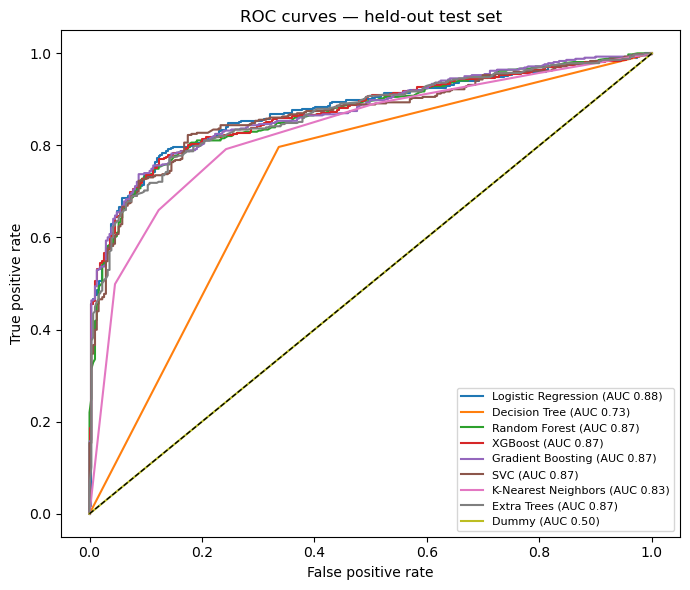

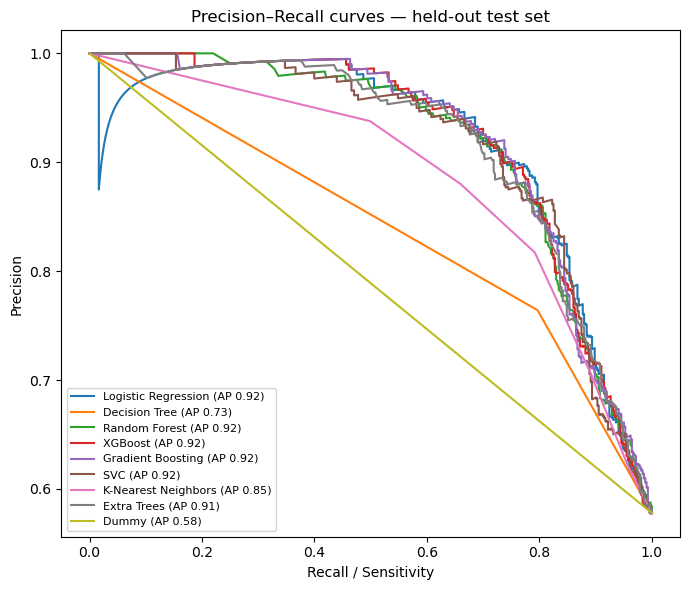

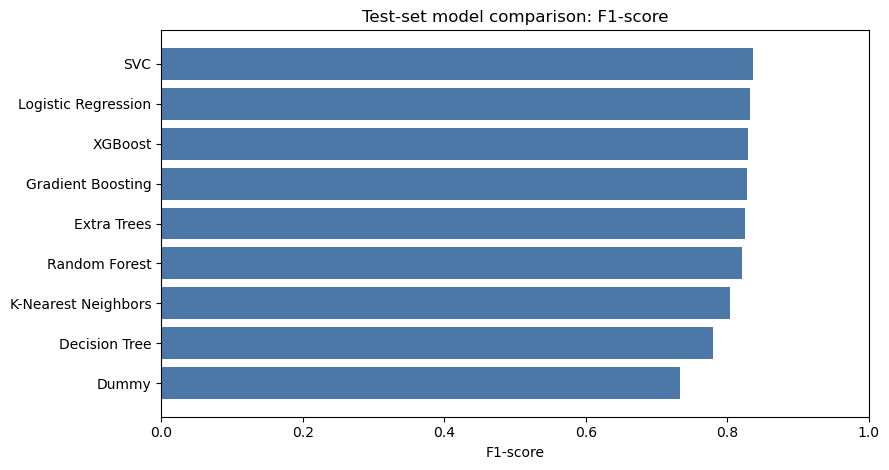

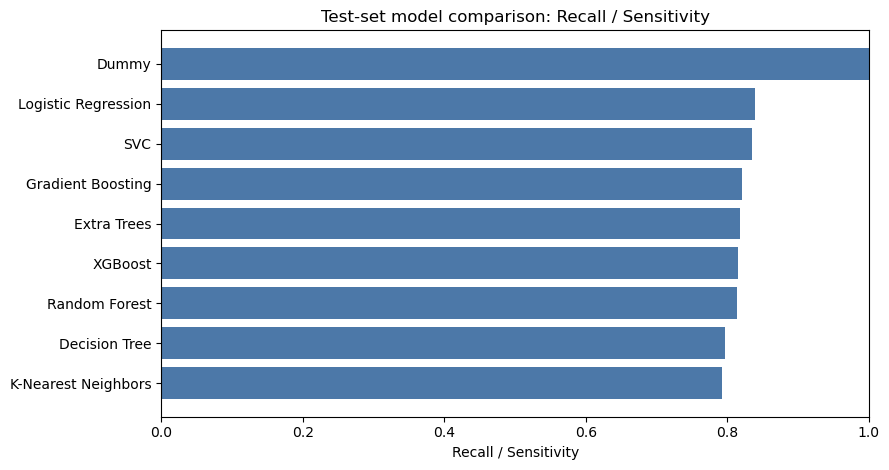

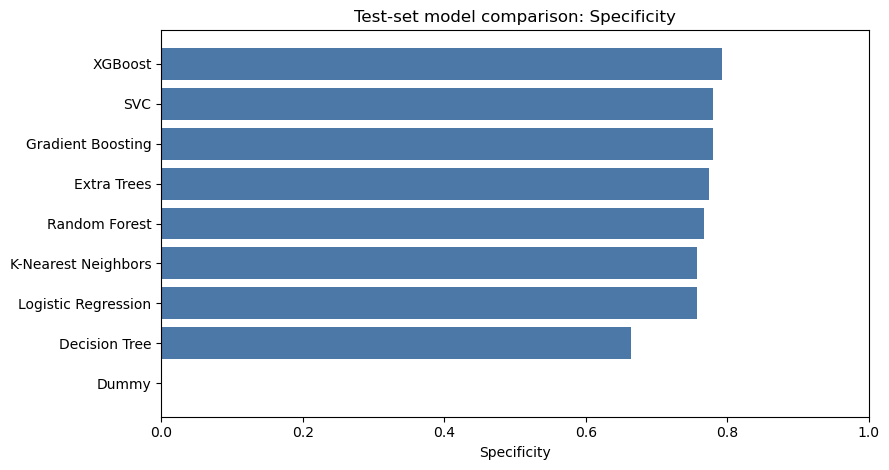

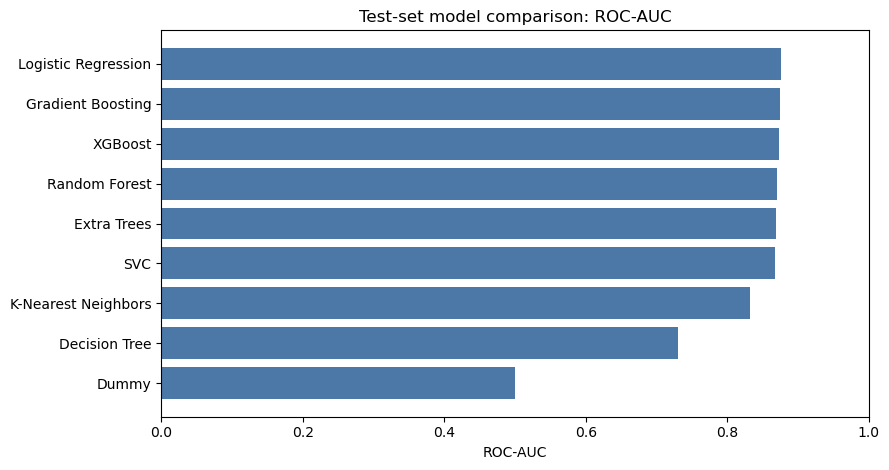

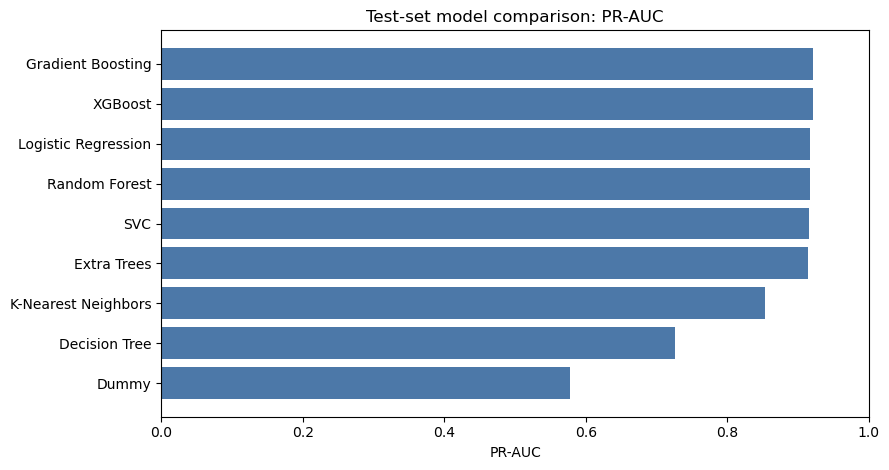

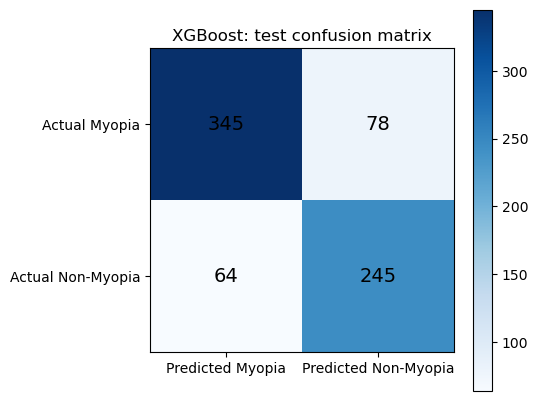

XGBoost: TP=345, TN=245, FP=64, FN=78; sensitivity=0.8156; specificity=0.7929
TP: myopia correctly classified. TN: non-myopia correctly classified. FP: non-myopia incorrectly labeled myopia. FN: myopia missed and labeled non-myopia.


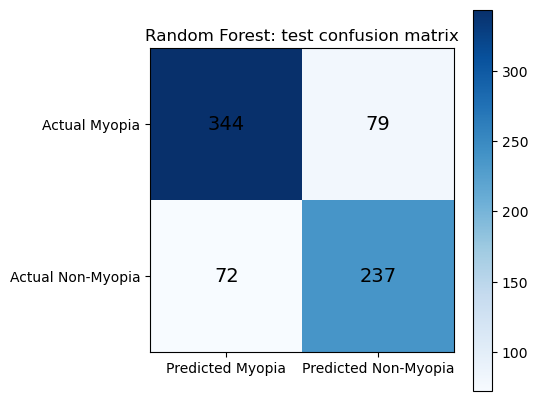

Random Forest: TP=344, TN=237, FP=72, FN=79; sensitivity=0.8132; specificity=0.7670
TP: myopia correctly classified. TN: non-myopia correctly classified. FP: non-myopia incorrectly labeled myopia. FN: myopia missed and labeled non-myopia.


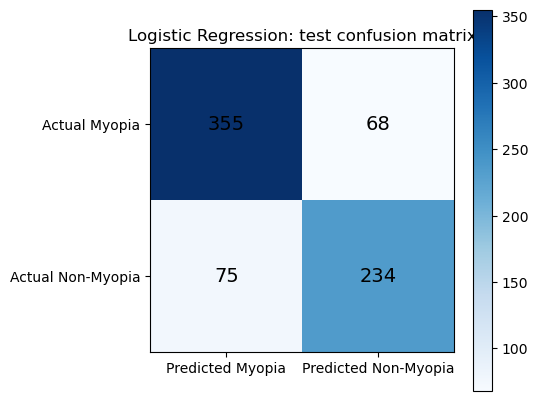

Logistic Regression: TP=355, TN=234, FP=75, FN=68; sensitivity=0.8392; specificity=0.7573
TP: myopia correctly classified. TN: non-myopia correctly classified. FP: non-myopia incorrectly labeled myopia. FN: myopia missed and labeled non-myopia.


,Threshold,Precision,Recall / Sensitivity,F1-score,Specificity
0,0.2,0.659504,0.943262,0.776265,0.333333
1,0.3,0.721689,0.888889,0.796610,0.530744
2,0.4,0.782609,0.851064,0.815402,0.676375
3,0.5,0.843521,0.815603,0.829327,0.792880
4,0.6,0.884718,0.780142,0.829146,0.860841
5,0.7,0.922840,0.706856,0.800535,0.919094
6,0.8,0.950000,0.628842,0.756757,0.954693


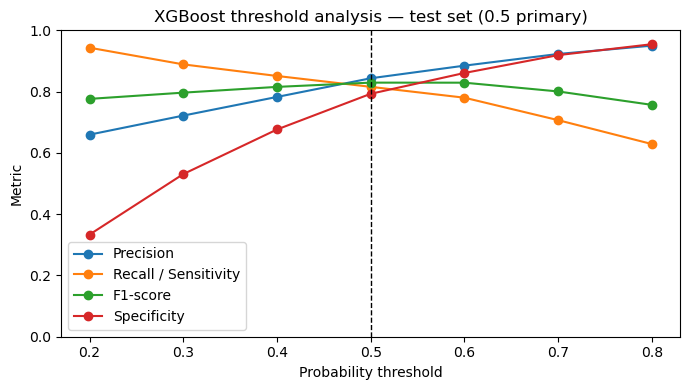

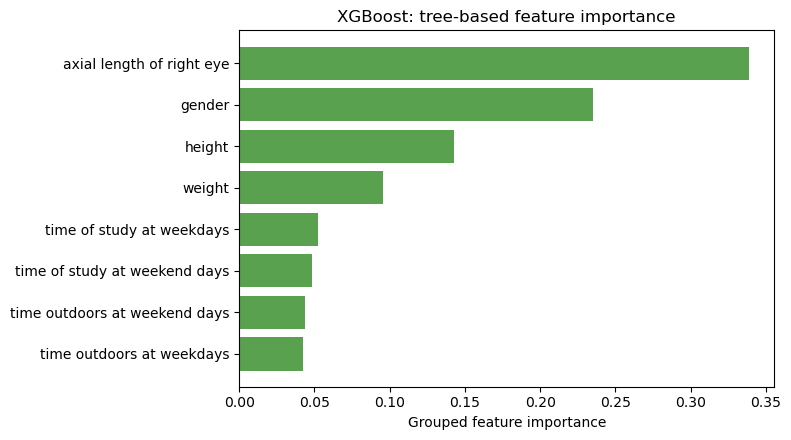

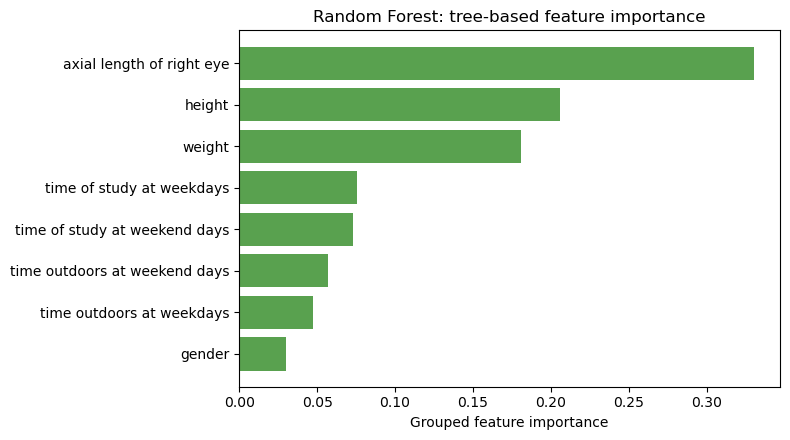

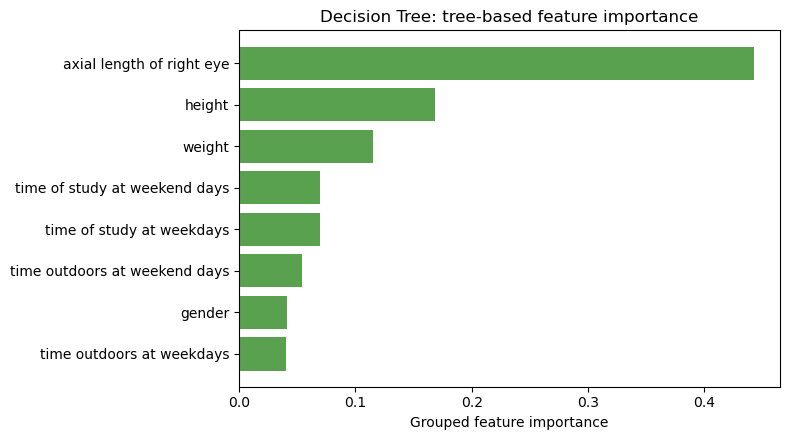

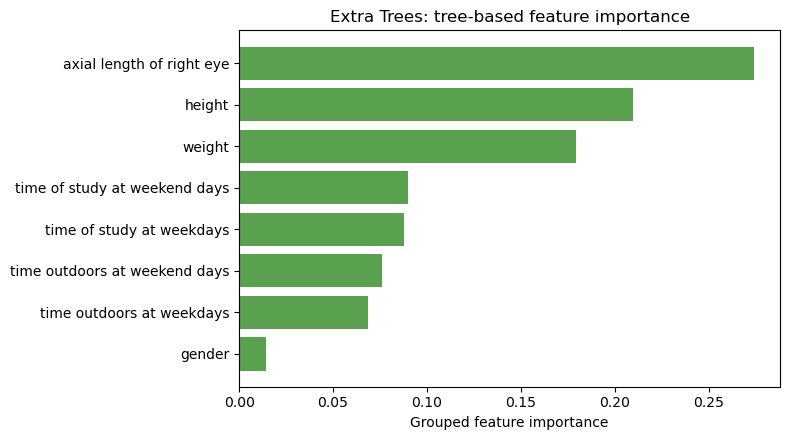

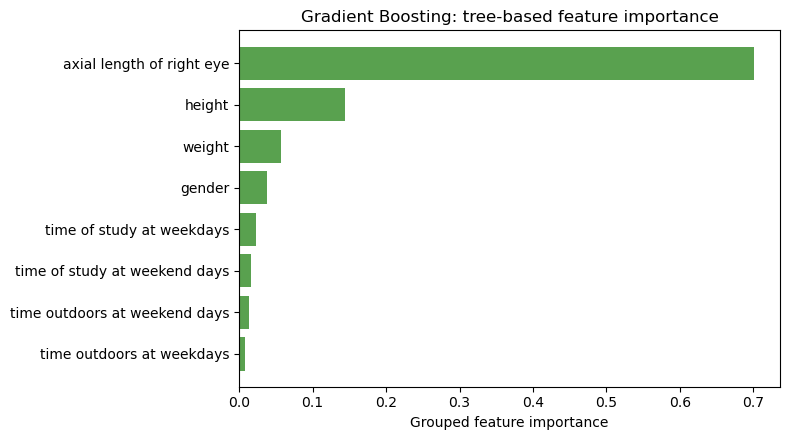

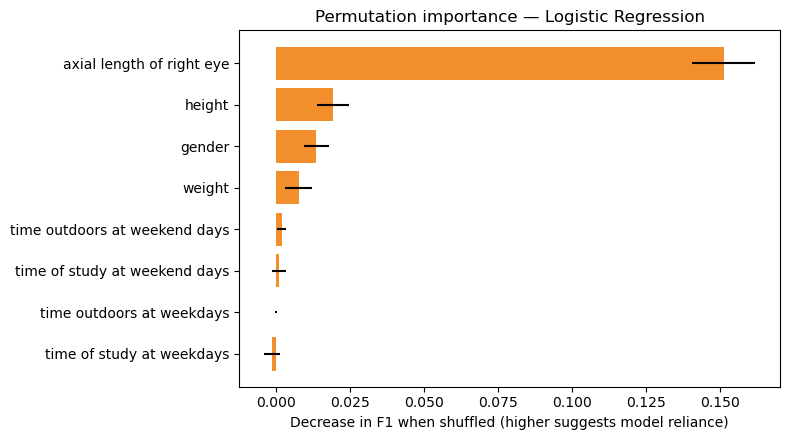

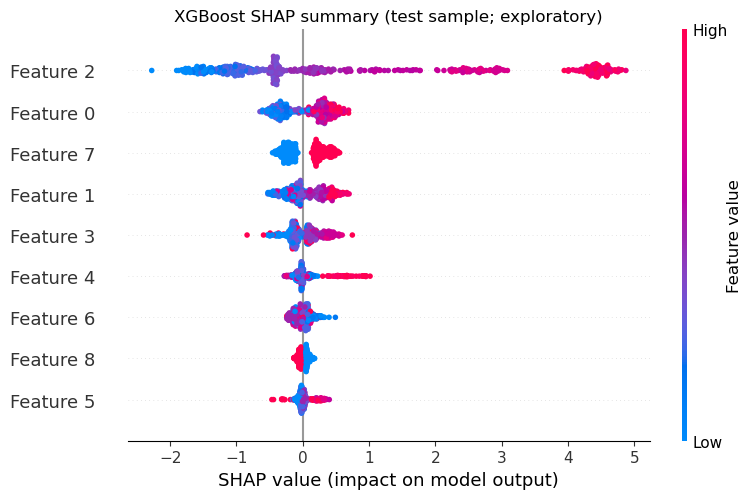


FINAL RESEARCH SUMMARY
Dataset: DATA.xls, 2018 sheet
Total usable labeled observations: 3658 (of 3658 source rows; 0 could not be labeled because sphere/cylinder was missing or nonnumeric).
Myopia: 2116; Non-Myopia: 1542
Target: provisional right-eye SER = sphere + cylinder/2; Myopia if SER <= -0.50 D. Operational research threshold; verify against clinical definition and measurement protocol.
Best-performing classifier selected using training five-fold OOF F1, then sensitivity, PR-AUC, specificity and ROC-AUC tie-breaks: Logistic Regression.
Held-out metrics: {'Accuracy': 0.8046448087431693, 'Precision': 0.8255813953488372, 'Recall / Sensitivity': 0.8392434988179669, 'Specificity': 0.7572815533980582, 'F1-score': 0.8323563892145369, 'ROC-AUC': 0.8754848630907296, 'PR-AUC': 0.9173064762334038}
Correctly classified: 589 of 732; myopia missed (FN): 68; non-myopia incorrectly labeled myopia (FP): 75.
Confusion matrix: TP=355, TN=234, FP=75, FN=68. TP/TN are correct labels; FP is a false 

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
import sklearn, xgboost, joblib

SEED=42
ROOT=Path.cwd()
if not (ROOT/'DATA.xls').exists(): ROOT=ROOT.parent
RESULTS=ROOT/'outputs/results'; RESULTS.mkdir(parents=True,exist_ok=True)
MODELS=ROOT/'outputs/models'; MODELS.mkdir(parents=True,exist_ok=True)
FIGURES=ROOT/'outputs/figures/classification'; FIGURES.mkdir(parents=True,exist_ok=True)
print({'scikit-learn':sklearn.__version__,'xgboost':xgboost.__version__})
try:
    data=pd.read_excel(ROOT/'DATA.xls',sheet_name='2018')
except ImportError:
    soffice=shutil.which('soffice') or '/Users/omvdangi/.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/soffice'
    temp=Path(tempfile.mkdtemp(prefix='myopia_classification_'))
    subprocess.run([soffice,'--headless','--convert-to','xlsx','--outdir',str(temp),str(ROOT/'DATA.xls')],check=True,capture_output=True,text=True)
    data=pd.read_excel(temp/'DATA.xlsx',sheet_name='2018')

sphere='spherical refraction of right eye'
cylinder='cylindrical refraction of right eye'
features=['gender','height','weight','axial length of right eye','time of study at weekdays','time of study at weekend days','time outdoors at weekdays','time outdoors at weekend days']
required=[sphere,cylinder]+features
missing=[c for c in required if c not in data.columns]
if missing: raise KeyError(f'Essential verified columns absent; stop before modeling: {missing}')
print('Verified columns:',required)
id_candidates=[c for c in data.columns if any(k in str(c).lower() for k in ['participant id','patient id','subject id','record id'])]
print('Potential participant/record ID columns:',id_candidates or 'none found by explicit name patterns')
print('Rows:',len(data),'exact duplicate rows retained:',int(data.duplicated().sum()))
# Preserve source missingness and sentinel-like values; do not guess that -1/-9 are missing.
raw=data[required].copy()
print('Source missing values:',raw.isna().sum().to_dict())
for c in [sphere,cylinder]+features[1:]: raw[c]=pd.to_numeric(raw[c],errors='coerce')
print('Non-numeric or missing after numeric parsing:',raw.isna().sum().to_dict())
print('Observed -1/-9 counts:',{c:{v:int((pd.to_numeric(raw[c],errors='coerce')==v).sum()) for v in [-1,-9]} for c in required})
print('Numeric range and quartiles for review (values are not automatically declared invalid):')
display(raw[[sphere,cylinder]+features[1:]].describe(percentiles=[.01,.25,.5,.75,.99]).T[['min','1%','25%','50%','75%','99%','max']])
print('The -1/-9 refraction values are retained because their meanings cannot be established from this workbook alone; verify their coding before clinical interpretation. Their inclusion may affect target labels.')
# Target must be observable to create a label. Only these rows are ineligible; predictors may be imputed.
ser=raw[sphere]+raw[cylinder]/2
target_ok=raw[sphere].notna() & raw[cylinder].notna() & ser.notna()
excluded_target=int((~target_ok).sum())
if target_ok.sum()==0: raise ValueError('No records have both target components; target construction failed.')
y=(ser.loc[target_ok] <= -0.50).astype(int).rename('Myopia')
X=raw.loc[target_ok,features].copy()
X['gender']=X['gender'].astype('string')
if y.nunique()!=2 or y.value_counts().min()<5: raise ValueError('Both classes with at least five observations are required for stratified five-fold evaluation.')
print(f'Target-ineligible observations excluded because SER cannot be constructed: {excluded_target}; all such rows are counted explicitly.')
counts=y.value_counts().reindex([1,0],fill_value=0)
class_summary=pd.DataFrame({'Class':['Myopia','Non-Myopia'],'Count':[int(counts[1]),int(counts[0])],'Percentage':[100*counts[1]/len(y),100*counts[0]/len(y)]})
print('Total usable labeled observations:',len(y)); display(class_summary)
minority_share=min(counts)/len(y)
imbalanced=(minority_share<0.40)
print('Imbalance assessment:', 'meaningful class imbalance (minority < 40%)' if imbalanced else 'no pronounced imbalance by the prespecified 40% rule')
fig,ax=plt.subplots(figsize=(6,4)); ax.bar(['Myopia','Non-Myopia'],[counts[1],counts[0]],color=['#d95f59','#4c78a8']); ax.set(ylabel='Participants',title='Class distribution');
for i,v in enumerate([counts[1],counts[0]]): ax.text(i,v,f'{v} ({v/len(y):.1%})',ha='center',va='bottom')
fig.tight_layout(); fig.savefig(FIGURES/'class_distribution.png',dpi=180); plt.show(); plt.close(fig)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Stratified 80:20 split:',len(X_train),'training,',len(X_test),'test. Test data are not used until final evaluation.')
cat=['gender']; num=[c for c in features if c not in cat]
def make_pipe(est,scale=False):
    nums=[('imputer',SimpleImputer(strategy='median'))]
    if scale: nums.append(('scaler',StandardScaler()))
    prep=ColumnTransformer([('num',Pipeline(nums),num),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
    return Pipeline([('preprocess',prep),('model',est)])

cw='balanced' if imbalanced else None
pos_weight=float(counts[0]/counts[1]) if imbalanced else 1.0
estimators={
 'Logistic Regression':make_pipe(LogisticRegression(max_iter=3000,class_weight=cw,random_state=SEED),True),
 'Decision Tree':make_pipe(DecisionTreeClassifier(class_weight=cw,random_state=SEED)),
 'Random Forest':make_pipe(RandomForestClassifier(n_estimators=400,class_weight=cw,n_jobs=-1,random_state=SEED)),
 'XGBoost':make_pipe(XGBClassifier(n_estimators=300,max_depth=3,learning_rate=.05,subsample=.85,colsample_bytree=.85,scale_pos_weight=pos_weight,eval_metric='logloss',random_state=SEED,n_jobs=1,verbosity=0)),
 'Gradient Boosting':make_pipe(GradientBoostingClassifier(random_state=SEED)),
 'SVC':make_pipe(SVC(class_weight=cw,probability=True,random_state=SEED),True),
 'K-Nearest Neighbors':make_pipe(KNeighborsClassifier(n_neighbors=5),True),
 'Extra Trees':make_pipe(ExtraTreesClassifier(n_estimators=400,class_weight=cw,n_jobs=-1,random_state=SEED)),
 'Dummy':make_pipe(DummyClassifier(strategy='prior'))}
print('Class weighting:',cw,'; XGBoost scale_pos_weight:',pos_weight)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
def metric_row(name,truth,pred,prob):
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    return {'Model':name,'Accuracy':accuracy_score(truth,pred),'Precision':precision_score(truth,pred,zero_division=0),'Recall / Sensitivity':recall_score(truth,pred,zero_division=0),'Specificity':tn/(tn+fp) if tn+fp else np.nan,'F1-score':f1_score(truth,pred,zero_division=0),'ROC-AUC':roc_auc_score(truth,prob),'PR-AUC':average_precision_score(truth,prob)}
# Out-of-fold probabilities on training data: each fold fits its own preprocessing pipeline.
cv_rows=[]
for name,model in estimators.items():
    oof=cross_val_predict(model,X_train,y_train,cv=cv,method='predict_proba',n_jobs=1)[:,1]
    cv_rows.append(metric_row(name,y_train,(oof>=.5).astype(int),oof))
cv_table=pd.DataFrame(cv_rows).add_prefix('CV ')
print('Five-fold stratified training cross-validation (out-of-fold predictions):'); display(cv_table)
# Fit on the full training set, evaluate once on held-out test data.
for model in estimators.values(): model.fit(X_train,y_train)
test_prob={n:m.predict_proba(X_test)[:,1] for n,m in estimators.items()}
test_pred={n:(test_prob[n]>=.5).astype(int) for n in estimators}
comparison=pd.DataFrame([metric_row(n,y_test,test_pred[n],test_prob[n]) for n in estimators])
# Selection rule: test metrics are descriptive only; choose via training OOF, then report test evaluation.
# Prespecified ranking uses F1, then sensitivity, PR-AUC, specificity, with ROC-AUC as final tie-break.
cv_ranking=pd.DataFrame(cv_rows).sort_values(['F1-score','Recall / Sensitivity','PR-AUC','Specificity','ROC-AUC'],ascending=False)
selected=cv_ranking.iloc[0]['Model']
comparison.insert(1,'Selected on training OOF',comparison['Model'].eq(selected))
comparison.to_csv(RESULTS/'classification_model_comparison.csv',index=False)
display(comparison.sort_values('F1-score',ascending=False))

# Curves for all models on the untouched test set.
fig,ax=plt.subplots(figsize=(7,6))
for n in estimators:
 fpr,tpr,_=roc_curve(y_test,test_prob[n]); ax.plot(fpr,tpr,label=f'{n} (AUC {roc_auc_score(y_test,test_prob[n]):.2f})')
ax.plot([0,1],[0,1],'k--',lw=1); ax.set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curves — held-out test set'); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES/'roc_curves.png',dpi=180); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(7,6))
for n in estimators:
 p,r,_=precision_recall_curve(y_test,test_prob[n]); ax.plot(r,p,label=f'{n} (AP {average_precision_score(y_test,test_prob[n]):.2f})')
ax.set(xlabel='Recall / Sensitivity',ylabel='Precision',title='Precision–Recall curves — held-out test set'); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES/'precision_recall_curves.png',dpi=180); plt.show(); plt.close(fig)
for metric in ['F1-score','Recall / Sensitivity','Specificity','ROC-AUC','PR-AUC']:
 fig,ax=plt.subplots(figsize=(9,4.8)); q=comparison.sort_values(metric); ax.barh(q['Model'],q[metric],color='#4c78a8'); ax.set(xlim=(0,1),xlabel=metric,title=f'Test-set model comparison: {metric}'); fig.tight_layout(); fig.savefig(FIGURES/f'model_comparison_{metric.lower().replace("/","_").replace(" ","_")}.png',dpi=180); plt.show(); plt.close(fig)

# Confusion matrices for XGBoost, Random Forest, and selected classifier; rows actual, columns predicted.
def show_cm(name):
    cm=confusion_matrix(y_test,test_pred[name],labels=[1,0]) # displayed order: myopia then non-myopia
    tp,fn,fp,tn=int(cm[0,0]),int(cm[0,1]),int(cm[1,0]),int(cm[1,1])
    fig,ax=plt.subplots(figsize=(5.5,4.5)); im=ax.imshow(cm,cmap='Blues'); ax.set_xticks([0,1],['Predicted Myopia','Predicted Non-Myopia']); ax.set_yticks([0,1],['Actual Myopia','Actual Non-Myopia']);
    for (i,j),v in np.ndenumerate(cm): ax.text(j,i,f'{v}',ha='center',va='center',fontsize=14)
    ax.set_title(f'{name}: test confusion matrix'); fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(FIGURES/f'confusion_matrix_{name.lower().replace(" ","_")}.png',dpi=180); plt.show(); plt.close(fig)
    sensitivity=tp/(tp+fn) if tp+fn else np.nan; specificity=tn/(tn+fp) if tn+fp else np.nan
    print(f'{name}: TP={tp}, TN={tn}, FP={fp}, FN={fn}; sensitivity={sensitivity:.4f}; specificity={specificity:.4f}')
    print('TP: myopia correctly classified. TN: non-myopia correctly classified. FP: non-myopia incorrectly labeled myopia. FN: myopia missed and labeled non-myopia.')
    return {'Model':name,'TP':tp,'TN':tn,'FP':fp,'FN':fn,'Sensitivity from matrix':sensitivity,'Specificity from matrix':specificity}
cm_rows=[show_cm(n) for n in dict.fromkeys(['XGBoost','Random Forest',selected])]

# Threshold analysis uses XGBoost probabilities on training OOF predictions only to inform choices;
# listed test metrics are descriptive at fixed thresholds; 0.5 remains primary.
xgb_oof=cross_val_predict(estimators['XGBoost'],X_train,y_train,cv=cv,method='predict_proba',n_jobs=1)[:,1]
thresholds=[.20,.30,.40,.50,.60,.70,.80]
threshold_rows=[]
for t in thresholds:
 p=(test_prob['XGBoost']>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y_test,p,labels=[0,1]).ravel()
 threshold_rows.append({'Threshold':t,'Precision':precision_score(y_test,p,zero_division=0),'Recall / Sensitivity':tp/(tp+fn) if tp+fn else np.nan,'F1-score':f1_score(y_test,p,zero_division=0),'Specificity':tn/(tn+fp) if tn+fp else np.nan})
threshold_table=pd.DataFrame(threshold_rows); display(threshold_table)
fig,ax=plt.subplots(figsize=(7,4));
for m in ['Precision','Recall / Sensitivity','F1-score','Specificity']: ax.plot(threshold_table['Threshold'],threshold_table[m],marker='o',label=m)
ax.axvline(.5,color='black',linestyle='--',lw=1); ax.set(xlabel='Probability threshold',ylabel='Metric',ylim=(0,1),title='XGBoost threshold analysis — test set (0.5 primary)'); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES/'xgboost_threshold_analysis.png',dpi=180); plt.show(); plt.close(fig)

# Tree feature importance in original-feature groups by mean one-hot importance.
def grouped_tree_importance(name):
    pipe=estimators[name]; imp=pipe.named_steps['model'].feature_importances_; names=pipe.named_steps['preprocess'].get_feature_names_out()
    frame=pd.DataFrame({'transformed':names,'importance':imp}); frame['feature']=frame['transformed'].str.replace(r'^(num|cat)__','',regex=True).str.split('_').str[0]
    # Feature labels are mapped to source names robustly from transformer ordering.
    out=[]
    for feat in features:
       match=[v for v in names if v.startswith(('num__' if feat in num else 'cat__')+feat)]
       out.append({'feature':feat,'importance':float(sum(imp[list(names).index(v)] for v in match))})
    return pd.DataFrame(out).sort_values('importance',ascending=False)
tree_tables={}
for n in ['XGBoost','Random Forest','Decision Tree','Extra Trees','Gradient Boosting']:
 tab=grouped_tree_importance(n); tree_tables[n]=tab
 fig,ax=plt.subplots(figsize=(8,4.5)); z=tab.sort_values('importance'); ax.barh(z.feature,z.importance,color='#59a14f'); ax.set(xlabel='Grouped feature importance',title=f'{n}: tree-based feature importance'); fig.tight_layout(); fig.savefig(FIGURES/f'feature_importance_{n.lower().replace(" ","_")}.png',dpi=180); plt.show(); plt.close(fig)
# Permutation importance for selected pipeline, test set held strictly for this descriptive interpretation.
perm=permutation_importance(estimators[selected],X_test,y_test,n_repeats=20,random_state=SEED,scoring='f1',n_jobs=1)
perm_table=pd.DataFrame({'feature':features,'permutation importance mean':perm.importances_mean,'standard deviation':perm.importances_std}).sort_values('permutation importance mean',ascending=False)
fig,ax=plt.subplots(figsize=(8,4.5)); z=perm_table.sort_values('permutation importance mean'); ax.barh(z.feature,z['permutation importance mean'],xerr=z['standard deviation'],color='#f28e2b'); ax.set(xlabel='Decrease in F1 when shuffled (higher suggests model reliance)',title=f'Permutation importance — {selected}'); fig.tight_layout(); fig.savefig(FIGURES/'selected_model_permutation_importance.png',dpi=180); plt.show(); plt.close(fig)
# Optional SHAP for XGBoost; record failure without interrupting reproducible core analysis.
shap_status='not attempted'
try:
 import shap
 pipe=estimators['XGBoost']; transformed=pipe.named_steps['preprocess'].transform(X_test); names=pipe.named_steps['preprocess'].get_feature_names_out()
 explainer=shap.TreeExplainer(pipe.named_steps['model']); sv=explainer(transformed[:min(500,len(X_test))])
 shap.plots.beeswarm(sv,show=False,max_display=12); plt.title('XGBoost SHAP summary (test sample; exploratory)'); plt.tight_layout(); plt.savefig(FIGURES/'xgboost_shap_summary.png',dpi=180); plt.show(); plt.close(); shap_status='success'
except Exception as e:
 shap_status=f'not available: {type(e).__name__}: {e}'; print('SHAP skipped:',shap_status)

# Persist only requested fitted end-to-end pipelines.
joblib.dump(estimators['XGBoost'],MODELS/'xgboost_myopia_classifier.joblib')
joblib.dump(estimators['Random Forest'],MODELS/'random_forest_myopia_classifier.joblib')
report=pd.DataFrame([metric_row('XGBoost',y_test,test_pred['XGBoost'],test_prob['XGBoost'])])
report.to_csv(RESULTS/'xgboost_classification_report.csv',index=False)

best=comparison.set_index('Model').loc[selected]; tn,fp,fn,tp=confusion_matrix(y_test,test_pred[selected],labels=[0,1]).ravel()
print('\nFINAL RESEARCH SUMMARY')
print('Dataset: DATA.xls, 2018 sheet')
print(f'Total usable labeled observations: {len(y)} (of {len(data)} source rows; {excluded_target} could not be labeled because sphere/cylinder was missing or nonnumeric).')
print(f'Myopia: {int(counts[1])}; Non-Myopia: {int(counts[0])}')
print('Target: provisional right-eye SER = sphere + cylinder/2; Myopia if SER <= -0.50 D. Operational research threshold; verify against clinical definition and measurement protocol.')
print(f'Best-performing classifier selected using training five-fold OOF F1, then sensitivity, PR-AUC, specificity and ROC-AUC tie-breaks: {selected}.')
print('Held-out metrics:',{k:float(best[k]) for k in ['Accuracy','Precision','Recall / Sensitivity','Specificity','F1-score','ROC-AUC','PR-AUC']})
print(f'Correctly classified: {int(tp+tn)} of {len(y_test)}; myopia missed (FN): {int(fn)}; non-myopia incorrectly labeled myopia (FP): {int(fp)}.')
print(f'Confusion matrix: TP={int(tp)}, TN={int(tn)}, FP={int(fp)}, FN={int(fn)}. TP/TN are correct labels; FP is a false myopia label; FN is missed myopia.')
print('Top selected-model permutation features:',perm_table.head(5).feature.tolist())
print('Class imbalance influenced class_weight and XGBoost scale_pos_weight only when minority share <40%; sentinel-like codes were retained without recoding.')
print('Limitations: operational target not clinically verified; variable units/codes and timing require source documentation; participant repeat status cannot be confirmed where no ID column exists; single source cohort and no external validation; model importance is not causal.')
print('These results are exploratory and do not establish clinical diagnostic validity.')
print('SHAP status:',shap_status)
print('Saved comparison, XGBoost report, requested models, and figures under outputs/.')


## Interpretation and limitations

The final cell prints the prespecified summary, confusion matrix definitions, test metrics, top permutation features, and research limitations. Feature importance describes fitted-model reliance and does not establish causal relationships. Any alternative XGBoost threshold is descriptive here; 0.5 remains the primary result, and test-set threshold results must not be used to select a threshold. SHAP is attempted when package compatibility permits.
